In [2]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_PATH = "/content/drive/MyDrive/Colab Notebooks/IDSE_PROJECT"

DATA_PATH = os.path.join(PROJECT_PATH, "processed_data")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULT_PATH = os.path.join(PROJECT_PATH, "results")

os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(RESULT_PATH, exist_ok=True)

print("Project folder connected successfully")


Mounted at /content/drive
Project folder connected successfully


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cleaned_df = pd.read_csv(
    os.path.join(DATA_PATH, "cleaned_online_retail.csv")
)

print(cleaned_df.shape)
cleaned_df.head()

(397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


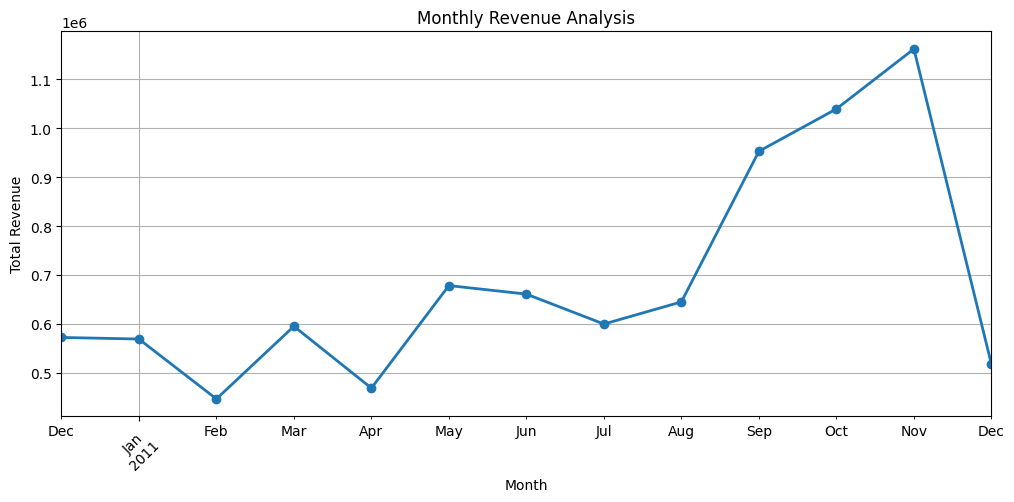

In [4]:
cleaned_df["InvoiceDate"] = pd.to_datetime(
    cleaned_df["InvoiceDate"]
)

cleaned_df["Month"] = (
    cleaned_df["InvoiceDate"].dt.to_period("M")
)

monthly_sales = cleaned_df.groupby(
    "Month"
)["Revenue"].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.savefig(
    os.path.join(RESULT_PATH, "monthly_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

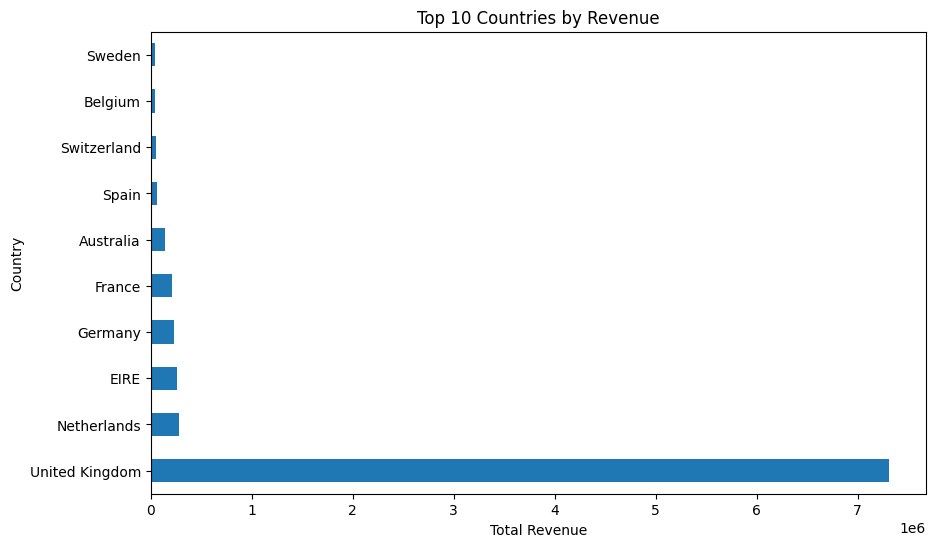

Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64


In [6]:
country_sales = cleaned_df.groupby(
    "Country"
)["Revenue"].sum()

country_sales = country_sales.sort_values(
    ascending=False
)

top_countries = country_sales.head(10)

plt.figure(figsize=(10, 6))

top_countries.plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.gca().invert_yaxis()

plt.savefig(
    os.path.join(RESULT_PATH, "country_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(top_countries)